# Exploring Outbreak Dynamics

## Introduction

This notebook explores the dynamics of infectious disease transmission through a hypothetical outbreak of **Slurry-Throat Congestion (STC)**.

STC is an entirely fictional infectious condition characterized by the sensation of a thick, sticky, oatmeal-like substance coating the throat.

**STC is entirely fictional.** Its transmission characteristics, infectious period, recovery dynamics, and responses to public health interventions are hypothetical parameters selected for computational experimentation. No real pathogen, clinical syndrome, or observed outbreak is being modeled.

The simulations use the 2025 Vintage Estimates of the Resident Population for Counties and 2025 TIGER/Line Shapefiles. The original data sources are available from the [U.S. Census Bureau population estimates](https://www.census.gov/data/tables/time-series/demo/popest/2020s-counties-total.html) and [2025 TIGER/Line Shapefiles](https://www.census.gov/geographies/mapping-files/2025/geo/tiger-line-file.html).

Using these datasets, the simulations explore how epidemic dynamics change under different assumptions about transmission, population mixing, geographic connectivity, isolation, quarantine, and intervention timing.

The objective is not to forecast an actual outbreak, but to develop an intuitive and quantitative understanding of infectious disease modeling, progressing from classical susceptible–infectious–removed (SIR) models to geographically structured simulations.

## Data Loading and Setup

We use 2025 U.S. Census county population estimates and TIGER/Line geographic data to define the population and spatial structure of the simulations.

The processed datasets contain county-level population estimates, geographic identifiers, coordinates, and county adjacency relationships for the Contiguous United States (lower 48 states). These were constructed using `dataset_builder.py`.

All simulations use the same underlying population data, beginning with a single nationally aggregated population and progressing toward geographically structured models.

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from pathlib import Path
from scipy.integrate import solve_ivp

# Load processed datasets

DATA_DIR = Path("Data_Processed")

counties = pd.read_csv(
    DATA_DIR / "counties.csv",
    dtype={"fips": str, "state_fips": str}
)

# DON'T NEED THIS YET

# edges = pd.read_csv(
#     DATA_DIR / "edges.csv",
#     dtype={"source_fips": str, "target_fips": str}
# )

geography = gpd.read_file(
    DATA_DIR / "county_network.geojson"
)

geography["fips"] = geography["fips"].astype(str).str.zfill(5)

# Validate datasets

assert counties["fips"].is_unique, "Duplicate county FIPS codes"
assert counties["population_2025"].notna().all(), "Missing populations"
assert (counties["population_2025"] > 0).all(), "Invalid populations"

# assert set(edges["source_fips"]).issubset(counties["fips"])
# assert set(edges["target_fips"]).issubset(counties["fips"])
assert set(geography["fips"]) == set(counties["fips"])

# Define total population

N = int(counties["population_2025"].sum())

print(f"Counties: {len(counties):,}")
# print(f"Border connections: {len(edges):,}")
print(f"Population (2025): {N:,}")

Counties: 3,108
Population (2025): 338,921,122


# 1. The Simplest Outbreak: Introducing the SIR Model

Before introducing geographic transmission or public health interventions, we begin with a classical **susceptible–infectious–removed (SIR)** model.

The SIR model divides a population into three compartments:

- **Susceptible ($S$)**: Individuals who have not been infected and remain susceptible to Disease STC.
- **Infectious ($I$)**: Individuals currently infected with STC who can transmit the disease.
- **Removed ($R$)**: Individuals who have recovered or otherwise left the infectious population and can no longer transmit STC.

Individuals transition from susceptible to infectious through transmission, and from infectious to removed through recovery or removal.

For this initial simulation, we make several simplifying assumptions:

1. The population is closed, with no births, deaths, or migration.

2. Individuals mix homogeneously, meaning that every individual has the same opportunity for infectious contact.

3. Transmission and removal rates remain constant throughout the outbreak.

4. Removed individuals cannot become susceptible again.

5. There is no incubation period, so newly infected individuals enter the infectious compartment immediately.

Although these assumptions are unrealistic for most infectious diseases, they provide a useful starting point for understanding how epidemics develop.

## 1.1 Mathematical Formulation

The classical SIR model describes how individuals move between three compartments over time: susceptible ($S$), infectious ($I$), and removed ($R$).

Rather than calculating the number of individuals in each compartment directly, the model first calculates **how quickly each compartment is changing**. These rates of change are described using ordinary differential equations.

### Model parameters

We begin with the following hypothetical values for STC:

| Symbol | Description | Value |
|---|---|---|
| $N$ | Total population | Sum of 2025 county populations |
| $S_0$ | Initially susceptible | $N-100$ |
| $I_0$ | Initially infectious | 100 people |
| $R_{\mathrm{initial}}$ | Initially removed | 0 people |
| $\beta$ | Effective transmission-rate parameter | 0.30 per day |
| $\gamma$ | Per-capita removal rate | 0.10 per day |
| $t$ | Time | Days |

The population remains constant throughout the simulation:

$$
N=S+I+R
$$

The notation $dS/dt$, $dI/dt$, and $dR/dt$ represents the instantaneous rate of change in each compartment, measured in people per day. A positive value indicates an increasing population, while a negative value indicates a decreasing population. These equations calculate rates of change, not the exact number of people in each compartment on the following day.

### Susceptible population

$$
\frac{dS}{dt}=-\beta\frac{SI}{N}
$$

The susceptible population decreases as individuals become infected.

The expression $\beta SI/N$ calculates the rate of new infections based on the current susceptible population, infectious population, and transmission parameter. The negative sign indicates that these infections remove individuals from the susceptible compartment.

### Infectious population

$$
\frac{dI}{dt}=\beta\frac{SI}{N}-\gamma I
$$

The infectious population changes through two competing processes:

1. **New infections** increase the infectious population.
2. **Removals** decrease the infectious population.

If new infections occur faster than removals, the infectious population grows. If removals occur faster than new infections, the infectious population declines.

### Removed population

$$
\frac{dR}{dt}=\gamma I
$$

The removed population increases as infectious individuals recover or otherwise leave the infectious compartment.

With $\gamma=0.10$ per day, the model assumes that infectious individuals leave the compartment at a constant per-capita rate of 0.10 per day. Under this model, the average time spent infectious is:

$$
\frac{1}{\gamma}=\frac{1}{0.10}=10\text{ days}
$$

In [2]:
I0 = 100
R0_initial = 0
S0 = N - I0 - R0_initial

# Hypothetical STC transmission parameters

beta = 0.30     # Effective transmission rate (per day)
gamma = 0.10    # Removal rate (per day)
days = 200      # Days to run simulation

# SIR differential equation definition

def sir_model(t, y, beta, gamma, N):
    # Susceptible, Infected, and Removed counts
    S, I, R = y

    # Instantaneous rate of new infections (people per day)
    new_infections = beta * S * I / N

    # Instantaneous rate of new removals (people per day)

    new_removals = gamma * I

    return [
        # People can only be removed from suceptible
        -new_infections,
        # New infections increase infected and new removals decrease infected
        new_infections - new_removals,
        # People can only be added to removed
        new_removals
    ]

# Solve the model

t = np.arange(days + 1)

solution = solve_ivp(
    sir_model,
    # Loop from 0--201 (200 days)
    t_span=(0, days),
    # Initial parameters for day 0
    y0=[S0, I0, R0_initial],
    # Transmission rate, removal rate, total population
    args=(beta, gamma, N),
    t_eval=t,
    rtol=1e-8,
    atol=1e-8
)

if not solution.success:
    raise RuntimeError(solution.message)

results = pd.DataFrame({
    "day": solution.t,
    "S": solution.y[0],
    "I": solution.y[1],
    "R": solution.y[2]
})

## 1.2 Initial Outbreak Simulation

With the model equations defined, we can now simulate the spread of STC through the population.

We begin by introducing 100 infectious individuals into an otherwise susceptible population. Using hypothetical transmission and removal rates, we simulate changes in the three compartments over 200 days.

The model is implemented using Python's `solve_ivp()` function, which numerically solves the differential equations by evaluating how quickly each compartment changes over time.

The resulting estimates describe the number of susceptible, infectious, and removed individuals at each simulated day.

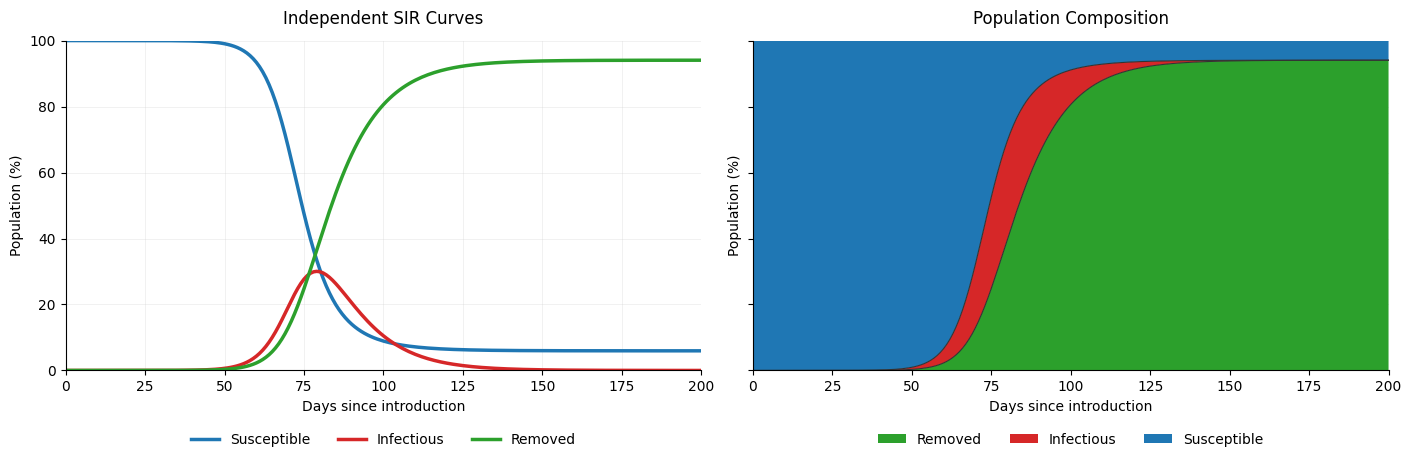

In [3]:
from notebook_helpers import (
    sir_curves_plot,
    sir_stacked_plot,
)
from notebook_helpers import (
    sir_curves_plot,
    sir_stacked_plot,
)
# Plots

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

# Independent SIR curves

sir_curves_plot(
    results,
    N,
    ax=axes[0],
    title="Independent SIR Curves",
)

# Population composite SIR cur

sir_stacked_plot(
    results,
    N,
    ax=axes[1],
    title="Population Composition",
)

plt.show()

### 1.2.1 Initial Outbreak Interpretation

The simulation illustrates how the population transitions between susceptible, infectious, and removed compartments over the course of an STC outbreak.

Initially, nearly the entire population is susceptible, with only 100 infectious individuals introduced into the population. As these individuals transmit STC to others, the infectious population gradually increases before entering a period of rapid growth.

As the outbreak progresses, the susceptible population declines while the removed population increases. The infectious population eventually reaches a maximum before declining toward zero, even though some individuals remain susceptible.

The two visualizations illustrate these dynamics differently. The independent curves show how each compartment changes over time, while the stacked plot illustrates how the population is distributed among the three compartments. At every point in the simulation, the three compartments collectively represent 100% of the population.

## 1.3 Exploring the Transmission Rate

Our initial simulation assumed a transmission-rate parameter of $\beta=0.30$ per day. However, this value was selected hypothetically, and different transmission rates may produce substantially different outbreak trajectories.

The transmission parameter ($\beta$) determines how quickly infections occur for a given number of susceptible and infectious individuals. Increasing $\beta$ increases the instantaneous rate of new infections, while decreasing it reduces that rate.

To investigate how transmission influences outbreak dynamics, we will simulate three scenarios:

| Scenario | Transmission rate ($\beta$) |
|---|---|
| Lower transmission | 0.15 |
| Baseline transmission | 0.30 |
| Higher transmission | 0.45 |

All other parameters and initial conditions will remain unchanged:

- Initial infectious population: 100 individuals
- Initial removed population: 0 individuals
- Removal rate ($\gamma$): 0.10 per day
- Population: 2025 contiguous U.S. population
- Simulation duration: 200 days

By changing only $\beta$, we can isolate its influence on the simulated outbreak.

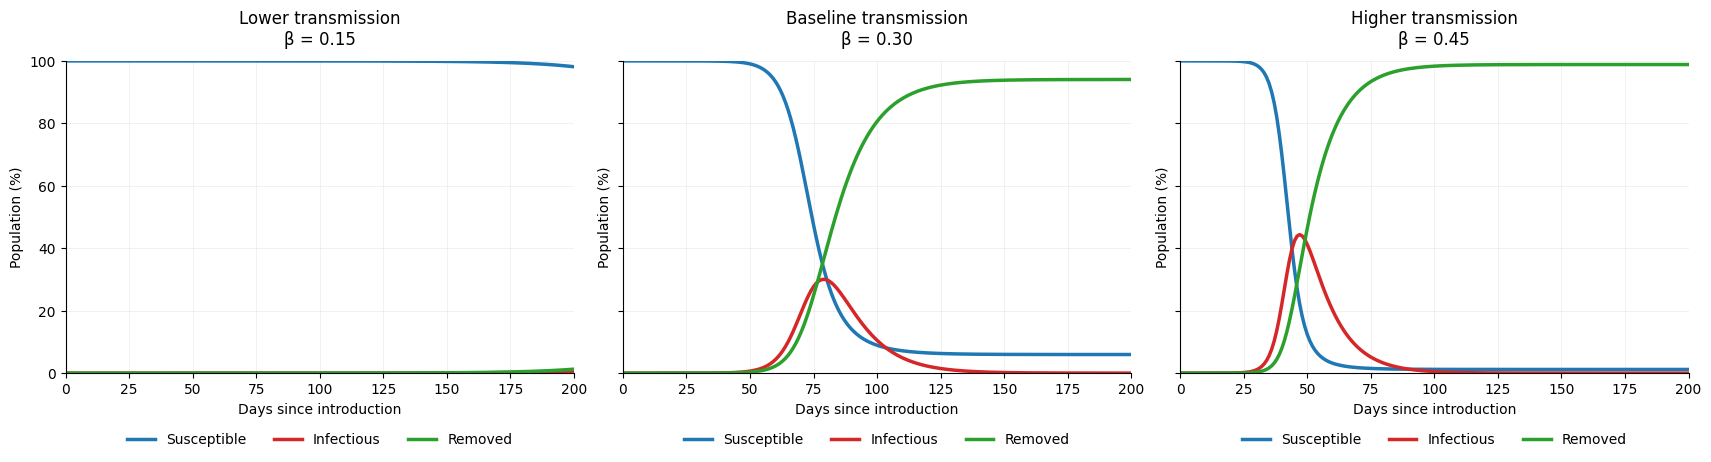

,Scenario,Transmission rate,Peak day,Peak infectious (%),Infected by day 200 (%)
0,Lower transmission,0.15,200,0.61,1.88
1,Baseline transmission,0.30,79,30.05,94.05
2,Higher transmission,0.45,47,44.35,98.83


In [4]:
# Define transmission scenarios
transmission_scenarios = {
    "Lower transmission": 0.15,
    "Baseline transmission": 0.30,
    "Higher transmission": 0.45,
}

# Store each simulation's results
transmission_results = {}

# Loop through scenarios
for scenario, beta_value in transmission_scenarios.items():

    # Solve SIR model
    solution = solve_ivp(
        sir_model,
        t_span=(0, days),
        y0=[S0, I0, R0_initial],
        args=(beta_value, gamma, N),
        t_eval=np.arange(days + 1),
        rtol=1e-8,
        atol=1e-8,
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    # Convert outcome to dataframe
    transmission_results[scenario] = pd.DataFrame({
        "day": solution.t,
        "S": solution.y[0],
        "I": solution.y[1],
        "R": solution.y[2],
    })

# Plotting simulations

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 4.5),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for ax, (scenario, beta_value) in zip(
    axes,
    transmission_scenarios.items()
):
    sir_curves_plot(
        transmission_results[scenario],
        N,
        ax=ax,
        title=f"{scenario}\nβ = {beta_value:.2f}",
    )

plt.show()

# Simulation statistics

summary = []

for scenario, result in transmission_results.items():

    peak_idx = result["I"].idxmax()

    summary.append({
        "Scenario": scenario,
        "Transmission rate": transmission_scenarios[scenario],
        "Peak day": result.loc[peak_idx, "day"],
        "Peak infectious (%)": (
            100 * result["I"].max() / N
        ),
        "Infected by day 200 (%)": (
            100 * (N - result["S"].iloc[-1]) / N
        ),
    })

transmission_summary = pd.DataFrame(summary)

display(transmission_summary.round(2))

### 1.3.1 Transmission Rate Scenario Interpretation

The scenarios show stark differences between all three transmission rates, with the lower-transmission scenario standing out in particular. In this scenario, the highest observed infectious prevalence occurs on the final day modeled, suggesting that the outbreak is still growing when the simulation ends. As a result, we cannot determine the actual peak of this outbreak from the 200-day simulation.

Meanwhile, the higher-transmission scenario reaches its peak 32 days earlier than the baseline, with a peak infectious prevalence 14.3 percentage points higher (44.35% compared with 30.05%). Furthermore, by the end of the 200-day simulation, approximately 98.83% of the population has experienced infection in the higher-transmission scenario, compared with 94.05% in the baseline.

These results suggest that increasing the transmission rate affects both the timing and magnitude of an outbreak. However, the lower-transmission scenario poses the question, **Does a lower transmission rate produce a longer-lasting epidemic?**

## 1.4 Measuring an Epidemic: Incidence, Prevalence, and Attack Rate

The different compartments ($S$, $I$, $R$), can be used to calculate epidemiologic measures that help describe and compare outbreaks for different epidemics. This aids us in further comparing the different transmission rate ($\beta$) outbreak scenarios.

The three basic comparative measures are **incidence, prevalence, and cumulative attack rate**.

### Incidence

Incidence describes the occurrence of new infections within a population over a specified period.

In our SIR model, susceptible individuals leave the susceptible compartment when they become infected. This allows us to calculate the number of new infections occurring between two observations by measuring the decrease in the susceptible population.

For consecutive daily observations:

$$
\text{New infections during day }t=S(t-1)-S(t)
$$

We can express this as a daily infection count per 100,000 population:

$$
\text{Daily infections per 100,000}=
\frac{S(t-1) - S(t)}{N} \times 100,000
$$

This provides a population-standardized measure of new infections during each day.

### Prevalence

Prevalence describes the proportion of a population experiencing a condition at a particular point in time.

In our model, we can calculate the proportion of individuals currently infectious:

$$
\text{Infectious prevalence (\%)}=\frac{I(t)}{N} \times 100
$$

Unlike incidence, which describes new infections, prevalence describes the number of individuals who are infectious at a particular moment.

A population may experience relatively few new infections while still having a substantial infectious population, particularly when individuals remain infectious for longer periods. Prevalence is typically higher than incidence for chronic diseases, while incidence is typically higher than prevalence for acute diseases.

### Cumulative Attack Rate

The cumulative attack rate is a measure of the proportion of an initially susceptible population that becomes infected during a defined outbreak period.

For our closed SIR model:

$$
\text{Cumulative attack rate (\%)}=
\frac{S(0) - S(t)}{S(0)} \times 100
$$

This measure describes the proportion of individuals who were susceptible at the beginning of the simulation and then became infected.

Unlike infectious prevalence, the cumulative attack rate does not decrease when individuals enter the removed compartment.

### Comparing the Measures

Although these measures describe the same outbreak, they answer different questions:

| Measure | Epidemiological question |
|---|---|
| Daily incidence | How many new infections are occurring? |
| Infectious prevalence | How many individuals are currently infectious? |
| Cumulative attack rate | What proportion of the initially susceptible population has been infected? |

We'll start by measuring these for the initial SIR model before moving to the different transmission rate (\beta) scenarios.

,day,S,I,R,daily_infections,incidence_per_100k,prevalence_pct,attack_rate_pct
0,0,3.389210e+08,100.000000,0.000000,NaN,NaN,0.000030,0.000000
1,1,3.389210e+08,122.140263,11.070137,33.210401,0.009799,0.000036,0.000010
2,2,3.389209e+08,149.182434,24.591232,40.563266,0.011968,0.000044,0.000022
3,3,3.389209e+08,182.211805,41.105932,49.544070,0.014618,0.000054,0.000036
4,4,3.389208e+08,222.553951,61.277028,60.513242,0.017855,0.000066,0.000054


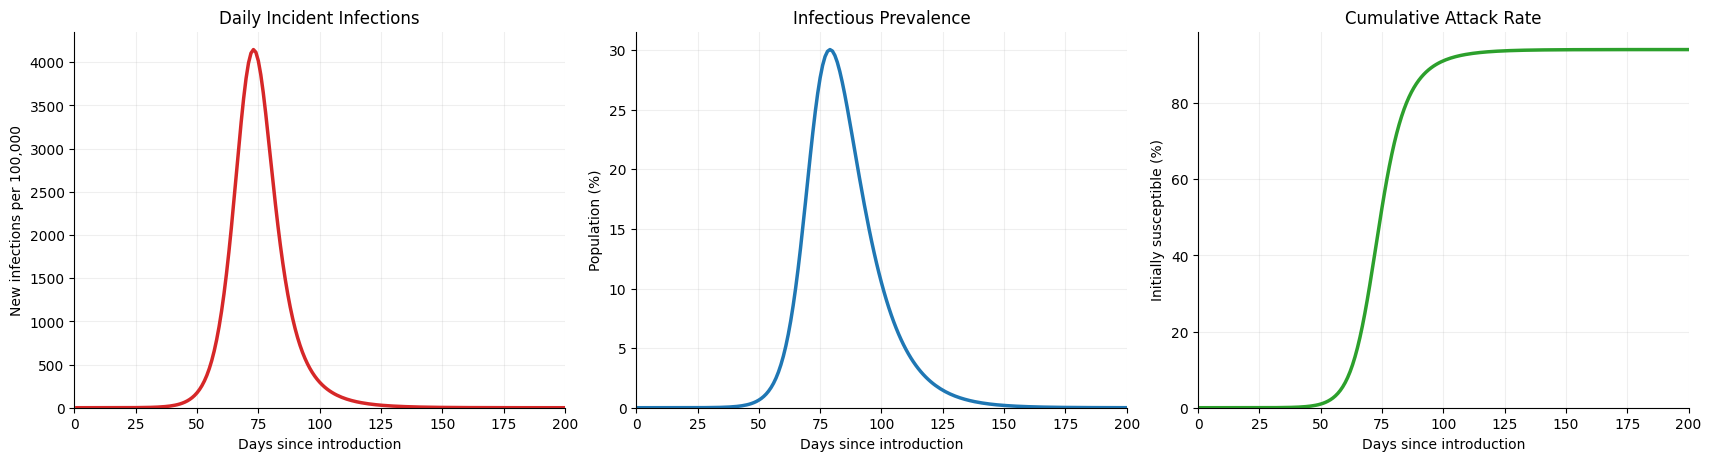

In [5]:
from notebook_helpers import (
    epidemiological_measures_plot
)

# Calculate epidemiological measures for the baseline outbreak
epi_results = results.copy()

# New infections during each preceding one-day interval
epi_results["daily_infections"] = (
    -epi_results["S"].diff()
)

# Daily infections per 100,000 total population
epi_results["incidence_per_100k"] = (
    epi_results["daily_infections"] / N * 100_000
)

# Proportion of population currently infectious
epi_results["prevalence_pct"] = (
    epi_results["I"] / N * 100
)

# Proportion of initially susceptible individuals infected
epi_results["attack_rate_pct"] = (
    (S0 - epi_results["S"]) / S0 * 100
)

display(epi_results.head())

fig, axes = epidemiological_measures_plot(epi_results)